Q21. Create a Pandas DataFrame from a CSV file and transform data using apply() and map().

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('results.csv')

df['Gender'] = df['Gender'].map({'M': 'Male', 'F': 'Female'})
df['Name_Length'] = df['Name'].apply(len)
df['Marks_Sqrt'] = df['Marks'].apply(np.sqrt)
print(df.round(2))

    Name  Gender  Marks  Name_Length  Marks_Sqrt
0   Asha  Female     82            4        9.06
1   Ravi    Male     45            4        6.71
2  Meena  Female     67            5        8.19
3   John    Male     91            4        9.54
4  Kiran    Male     38            5        6.16
5   Sara  Female     74            4        8.60
6   Anil    Male     55            4        7.42
7  Divya  Female     60            5        7.75


Q22. Detect missing values, handle them appropriately, detect possible outliers, and standardize numerical features.

In [3]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('people.csv')
print(df.isnull().sum())

df = df.fillna(df.median(numeric_only=True))

q1 = df['Weight'].quantile(0.25)
q3 = df['Weight'].quantile(0.75)
iqr = q3 - q1
print(df[(df['Weight'] < q1 - 1.5 * iqr) | (df['Weight'] > q3 + 1.5 * iqr)])

scaler = StandardScaler()
df[['Age', 'Weight', 'Height']] = scaler.fit_transform(df[['Age', 'Weight', 'Height']])
print(df.round(2))

Name      0
Age       1
Weight    1
Height    1
dtype: int64
  Name   Age  Weight  Height
7    H  40.0   200.0   180.0
  Name   Age  Weight  Height
0    A -1.44   -0.50   -1.38
1    B -0.22   -0.30   -0.21
2    C -0.71   -0.37   -0.68
3    D -0.22   -0.25    0.26
4    E  1.00   -0.20    0.96
5    F  0.27   -0.30   -0.21
6    G -0.46   -0.40   -0.44
7    H  2.21    2.99    2.13
8    I -0.95   -0.45   -1.15
9    J  0.51   -0.22    0.72


Q23. Create a line plot and a scatter plot with a regression line to show trends between two numerical variables.

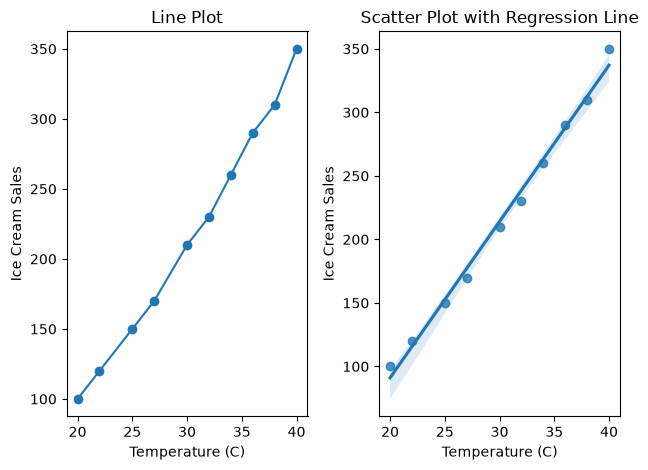

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('icecream.csv')

plt.subplot(1, 2, 1)
plt.plot(df['Temperature'], df['Sales'], marker='o')
plt.xlabel('Temperature (C)')
plt.ylabel('Ice Cream Sales')
plt.title('Line Plot')

plt.subplot(1, 2, 2)
sns.regplot(x='Temperature', y='Sales', data=df)
plt.xlabel('Temperature (C)')
plt.ylabel('Ice Cream Sales')
plt.title('Scatter Plot with Regression Line')

plt.tight_layout()
plt.show()

Q24. Train a KNN classifier using at least three different K values. Compare their accuracy scores using a plot and identify the best result.


[0.6444444444444445, 0.6888888888888889, 0.7555555555555555, 0.7555555555555555, 0.7777777777777778]
Best K = 9


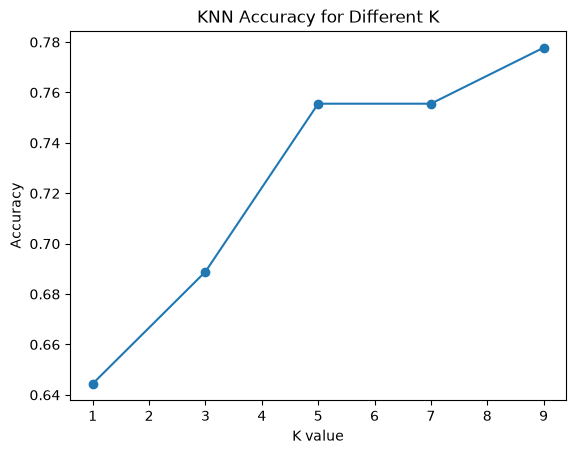

In [5]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = load_iris()
X = iris.data[:, :2]
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

k_values = [1, 3, 5, 7, 9]
scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    scores.append(model.score(X_test, y_test))

print(scores)
print('Best K =', k_values[scores.index(max(scores))])

plt.plot(k_values, scores, marker='o')
plt.xlabel('K value')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy for Different K')
plt.show()